In [1]:
from helpers import evaluation as ev
from datasets import load_dataset
from helpers import embedding as eb

import pandas as pd
import matplotlib.pyplot as plt
from google import genai

from dotenv import load_dotenv
from pathlib import Path
import os

try:
    load_dotenv()
    API_KEY = os.getenv("GOOGLE_API_KEY")
except Exception as e:
    print(f"Error loading environment variable(s): {e}")

PROJECT_ROOT = Path.cwd().parent
CHROMA_DIR = PROJECT_ROOT / "Data" / "chroma"
eval_client = genai.Client(api_key=API_KEY)
rows = [dict(r) for r in load_dataset("PatronusAI/financebench", split="train")]
collection = eb.get_collection(CHROMA_DIR)

## Retrieval evaluation

This test measures whether the retriever finds the page of the filing that contains the evidence for a question. It does not involve the language model. Each of the 150 FinanceBench questions comes with gold evidence: the document and page where the answer is found.

**Procedure.** For each question, the question text is embedded and the 10 closest pieces (`k = 10`) are retrieved from the vector store. The result is the *rank* of the first retrieved piece that lies on a gold evidence page. If no piece in the top 10 lies on a gold page, the rank is empty and the question counts as a miss.

**Search scopes.** The same test is run three times with different metadata filters:
- `none`: the whole collection is searched, with no filter.
- `company`: the search is restricted to the company named in the question.
- `doc`: the search is restricted to the exact filing the question refers to. This assumes the filing is already known, so it gives an upper bound on retrieval quality.

**Metrics.**
- `n`: the number of questions evaluated (150).
- `recall@k`: the share of questions whose gold page appears within the top *k* results. For example, `recall@5 = 0.92` means that 92% of questions have the evidence page among the first five results. It is reported at k = 1, 3, 5 and 10.
- `mrr` (mean reciprocal rank): the average of 1/rank over all questions, counting a miss as 0. A first-place hit scores 1, second place 0.5, third place 0.33, and so on. It ranges from 0 to 1 and rewards placing the gold page higher, which recall@k does not capture.

A page counts as a hit only if both the document name and the page number match. A different page of the same filing does not count.

In [4]:
out = PROJECT_ROOT / "Data" / "eval"
out.mkdir(exist_ok=True)

summaries, all_results = [], {}
for scope in ev.SCOPES:
    s, r = ev.retrieval_eval(rows, collection, eval_client, scope=scope, k=10,
                             out_path=out / f"retrieval_{scope}.json")
    summaries.append(s); all_results[scope] = r
pd.DataFrame(summaries).set_index("scope").round(3)

,n,mrr,recall@1,recall@3,recall@5,recall@10
scope,,,,,,
none,150,0.580,0.427,0.700,0.78,0.873
company,150,0.622,0.460,0.753,0.86,0.920
doc,150,0.677,0.513,0.820,0.92,0.967


## Analysis of missed questions

A question is a miss when its gold page is not in the top 10 retrieved pieces (`rank` is empty). This section lists the misses for the `doc` scope and groups them by filing and by question type.

The purpose is to see whether failures are spread evenly or concentrated, for example in certain filings, in table-heavy questions, or in documents where section detection found no headings. Questions that are found but ranked below 3 are a separate case: the right page was retrieved but placed too low, which is a ranking problem rather than a coverage problem.

Note that a miss means only that the *labelled* evidence page was not retrieved. A question may still be answerable from another page that contains the same figure, so the miss count slightly understates how well the system can answer.

Two limits are to be remembereding when you read the numbers. With 150 questions, one question is about 0.7 points of recall, so small differences between scopes are weak evidence. And recall@k here depends on k, which is fixed at 10 in the test, so numbers from a different k aren't comparable.


In [5]:
res = pd.DataFrame(all_results["doc"])
miss = res[res["rank"].isna()]
print(len(miss))
miss.groupby("doc_name").size().sort_values(ascending=False).head(10)

5


doc_name
PFIZER_2021_10K        2
BOEING_2022_10K        1
JPMORGAN_2021Q1_10Q    1
JPMORGAN_2022_10K      1
dtype: int64

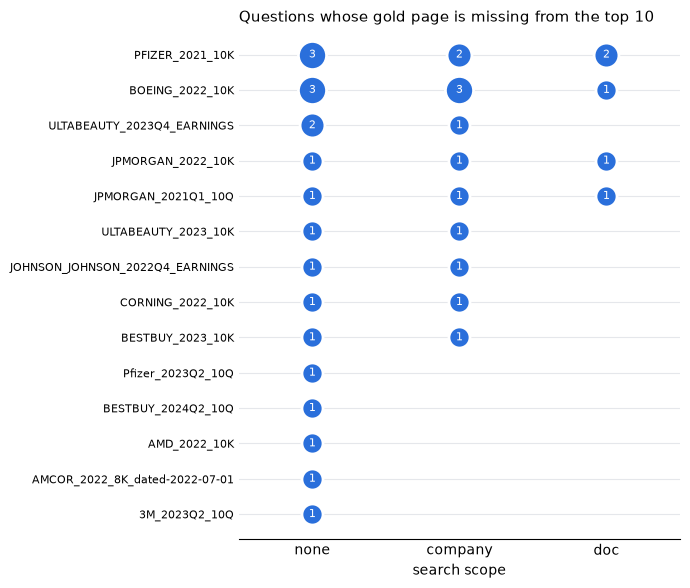

In [6]:
# one row per (scope, question): did the gold page fail to appear in the top 10?
df = pd.DataFrame(
    {"scope": scope, "doc_name": r["doc_name"], "missed": r["rank"] is None}
    for scope, results in all_results.items() for r in results
)

# misses per filing and scope; keep only filings with at least one miss
counts = (
    df[df["missed"]].groupby(["doc_name", "scope"]).size()
    .unstack(fill_value=0)
    .reindex(columns=list(ev.SCOPES), fill_value=0)
)
counts = counts.loc[counts.sum(axis=1).sort_values().index]   # worst filings at the top

fig, ax = plt.subplots(figsize=(7, 0.32 * len(counts) + 1.5))
for y, (doc, row) in enumerate(counts.iterrows()):
    for x, n in enumerate(row):
        if n:
            ax.scatter(x, y, s=140 + 90 * n, color="#2a6fdb", edgecolor="white", linewidth=2, zorder=3)
            ax.text(x, y, str(n), ha="center", va="center", color="white", fontsize=8, zorder=4)

ax.set_xticks(range(len(ev.SCOPES)), ev.SCOPES)
ax.set_yticks(range(len(counts)), counts.index, fontsize=8)
ax.set_xlim(-0.5, len(ev.SCOPES) - 0.5)
ax.set_ylim(-0.7, len(counts) - 0.3)
ax.grid(axis="y", color="#e5e7eb", zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.set_xlabel("search scope")
ax.set_title("Questions whose gold page is missing from the top 10", loc="left", fontsize=11)
plt.tight_layout()
plt.show()